# DivPrune vs FastV token highlights

Each row of figures compares the **same MME image and question** at the same retention ratio. DivPrune is on the left and FastV (K=3) is on the right. The answer under each image comes from that method’s JSON file.

Run the cells from top to bottom. The notebook reads the existing PNG and JSON files; it does not run model inference.


In [1]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Works when Jupyter starts in this folder or in the project root.
ROOT = Path.cwd()
if not (ROOT / "divprune").is_dir():
    ROOT = ROOT / "results" / "token_visualization"
if not (ROOT / "divprune").is_dir() or not (ROOT / "fastv").is_dir():
    raise FileNotFoundError("Start Jupyter in the project root or results/token_visualization")

RATIOS = ("r0.1", "r0.5", "r0.7")


def load_method(method, ratio):
    records = {}
    for json_path in sorted((ROOT / method / ratio).glob("*.json")):
        data = json.loads(json_path.read_text())
        request = data["request"]
        key = (request["doc_id"], request["image_id"], request["question"])
        image_path = json_path.with_suffix(".png")
        if not image_path.is_file():
            raise FileNotFoundError(image_path)
        if key in records:
            raise ValueError(f"Duplicate example in {method}/{ratio}: {key}")
        records[key] = {"image": image_path, "answer": data["response"]}
    return records


def paired_examples(ratio):
    divprune = load_method("divprune", ratio)
    fastv = load_method("fastv", ratio)
    if not divprune or divprune.keys() != fastv.keys():
        raise ValueError(f"The methods have different examples at {ratio}")
    return [(key, divprune[key], fastv[key]) for key in sorted(divprune)]


def show_ratio(ratio):
    pairs = paired_examples(ratio)
    display(Markdown(f"## Retention ratio: {float(ratio[1:]):.0%} ({len(pairs)} paired examples)"))
    for number, (key, divprune, fastv) in enumerate(pairs, 1):
        _, image_id, question = key
        fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
        fig.suptitle(f"{number}. {textwrap.fill(question, 95)}", fontsize=12, y=0.98)
        for ax, method, record in zip(axes, ("DivPrune", "FastV (K=3)"), (divprune, fastv)):
            ax.imshow(plt.imread(record["image"]))
            ax.set_title(method, fontsize=12, fontweight="bold")
            ax.set_xlabel(f"Answer: {record['answer']}", fontsize=11)
            ax.set_xticks([])
            ax.set_yticks([])
        fig.tight_layout(rect=(0, 0, 1, 0.88))
        display(fig)
        plt.close(fig)


## Retention ratio: 10% (10 paired examples)

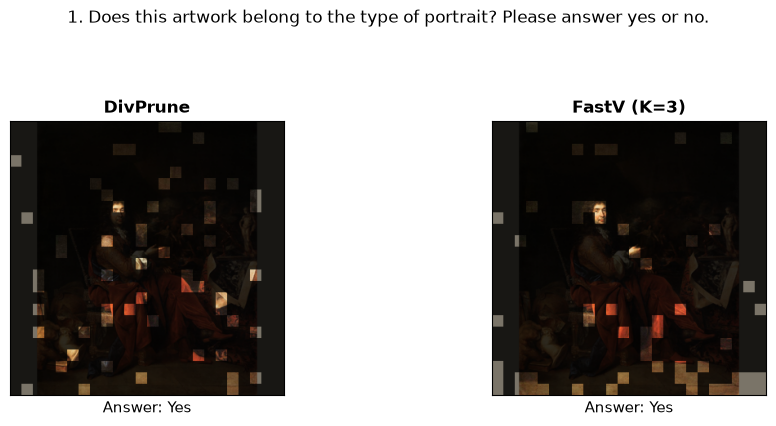

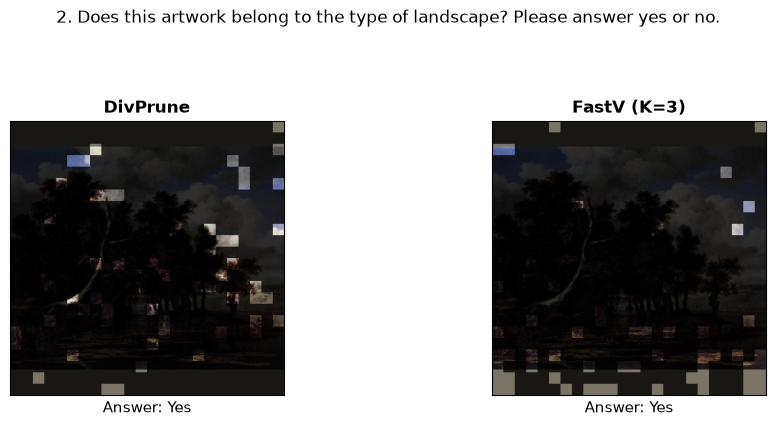

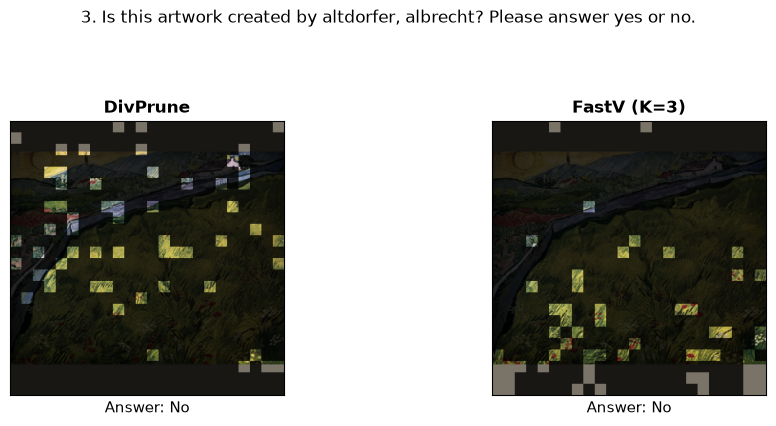

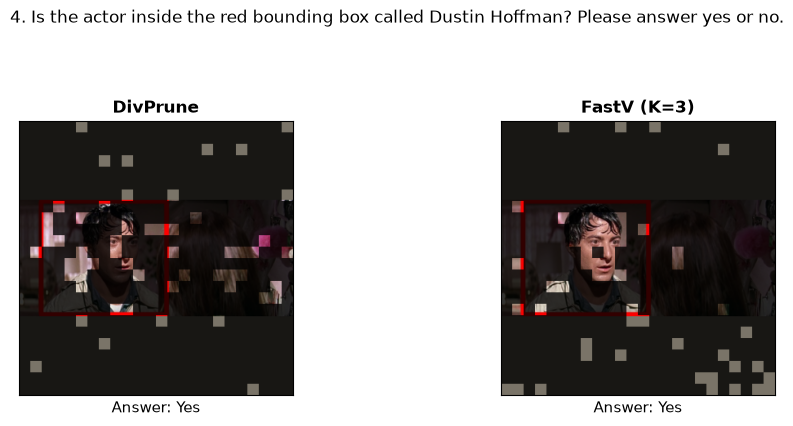

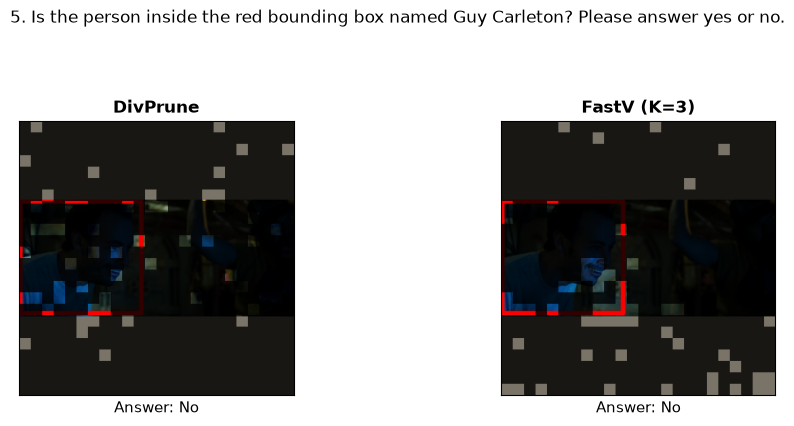

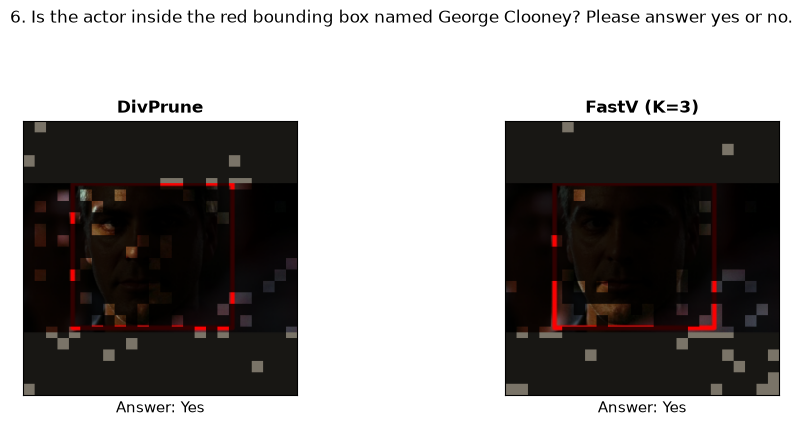

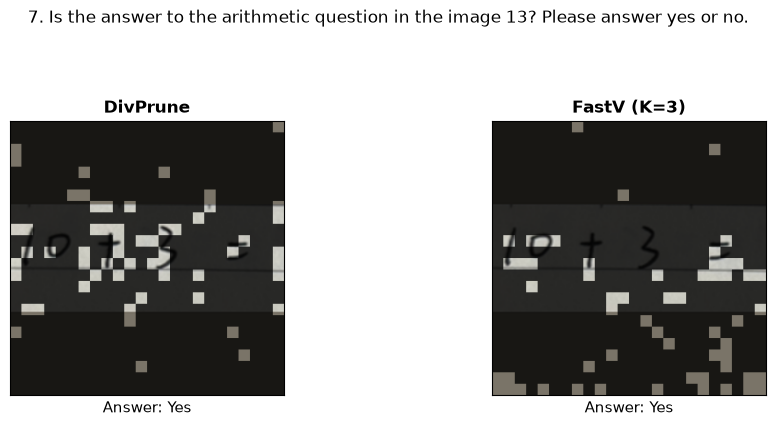

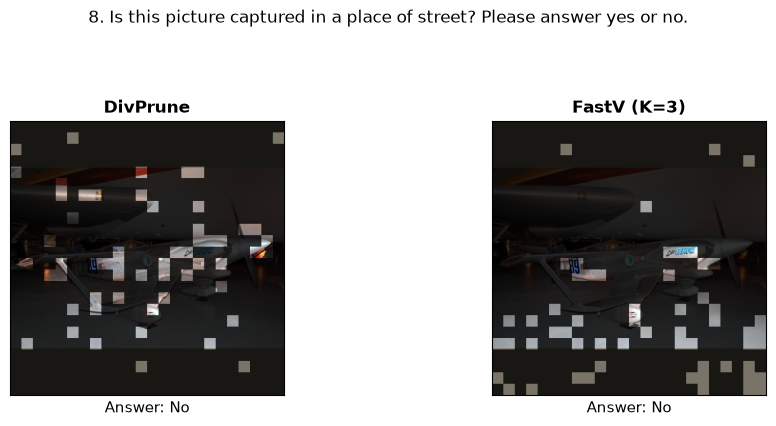

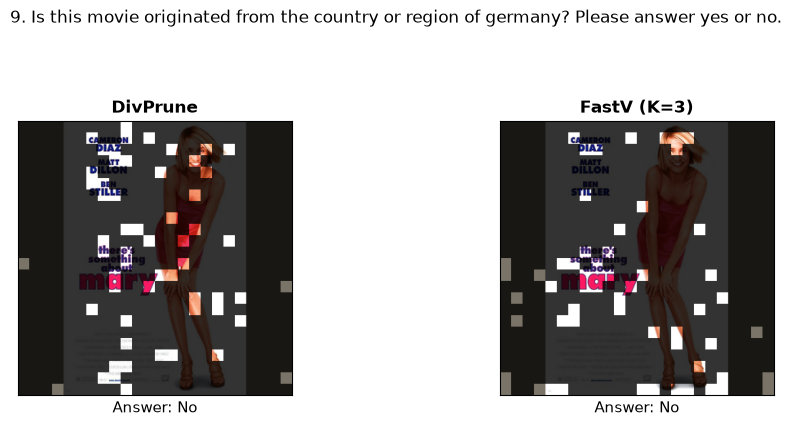

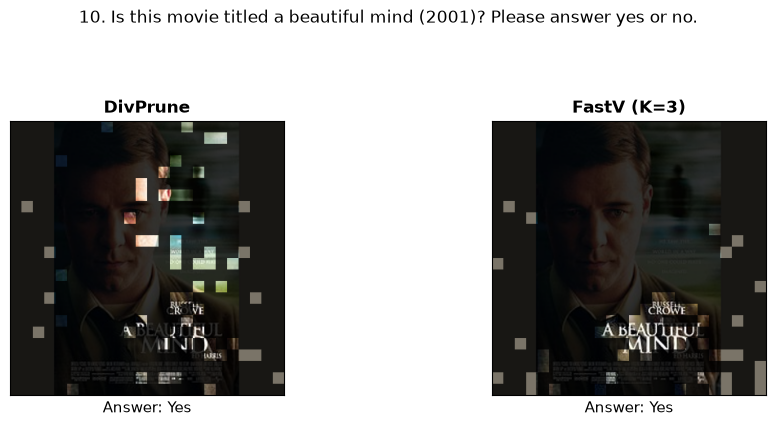

In [2]:
show_ratio("r0.1")


## Retention ratio: 50% (10 paired examples)

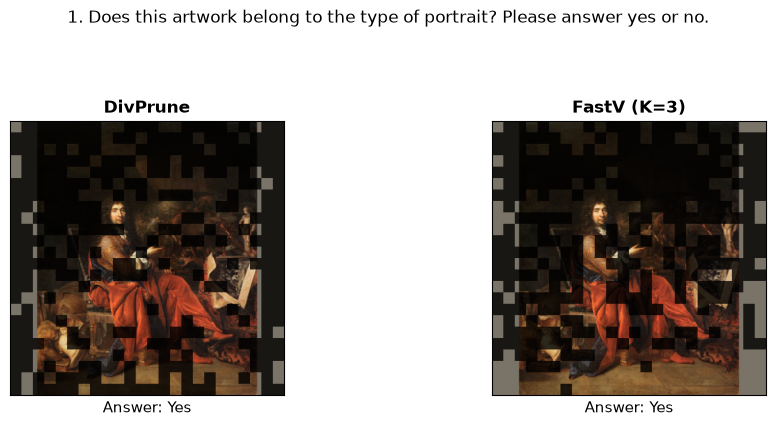

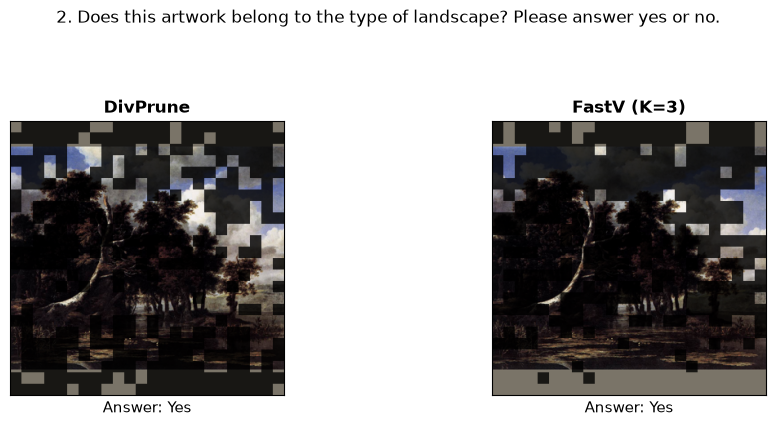

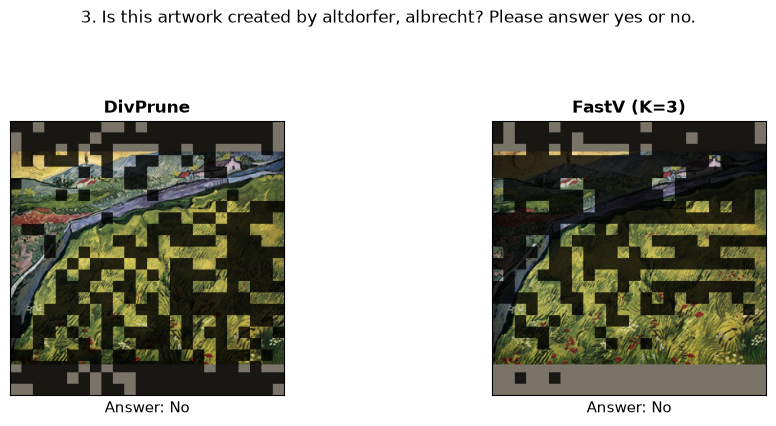

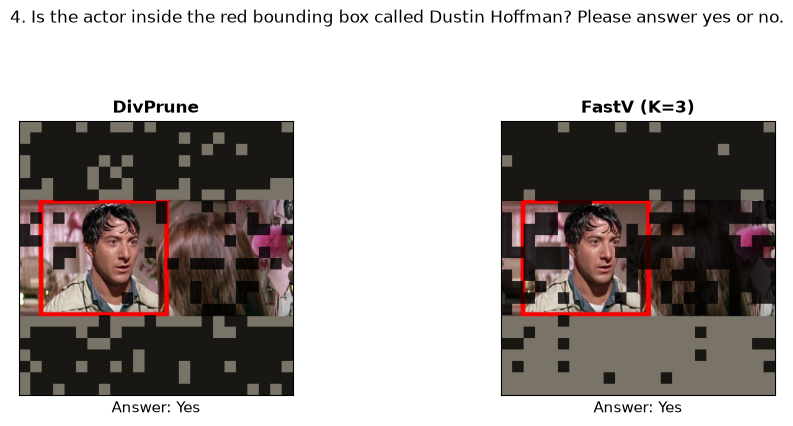

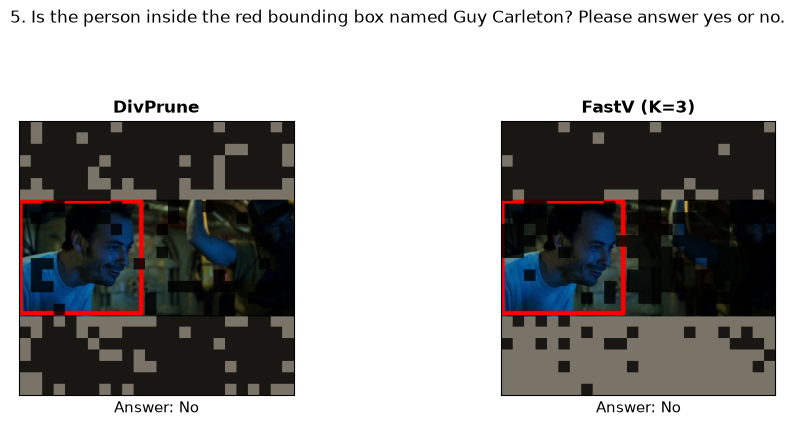

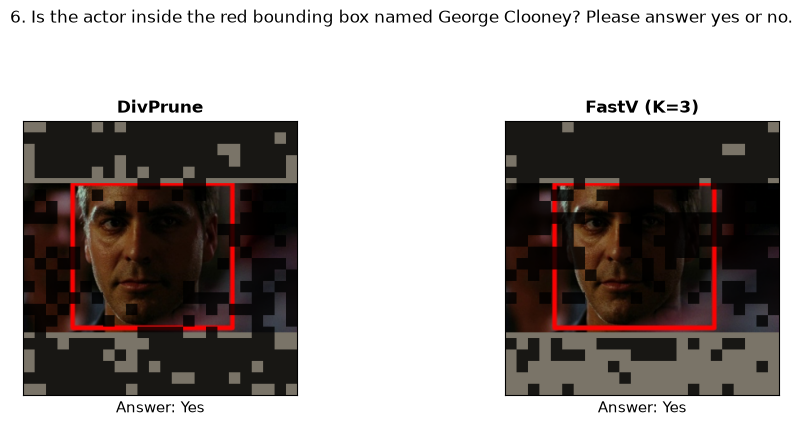

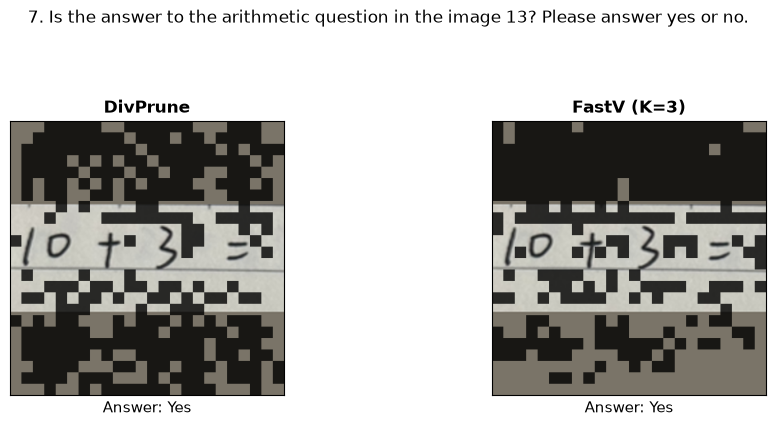

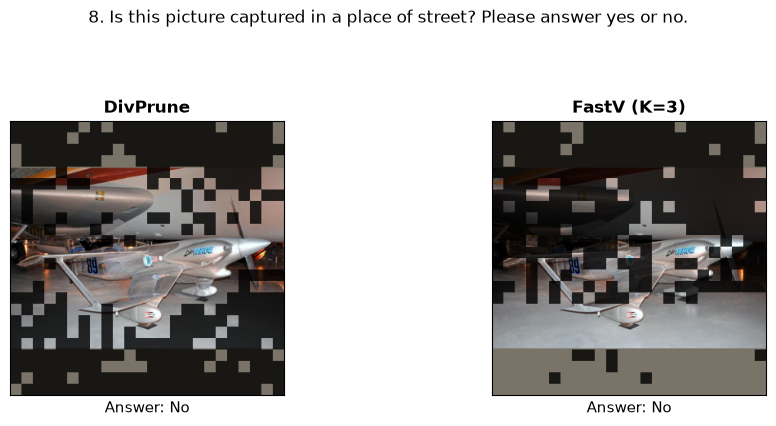

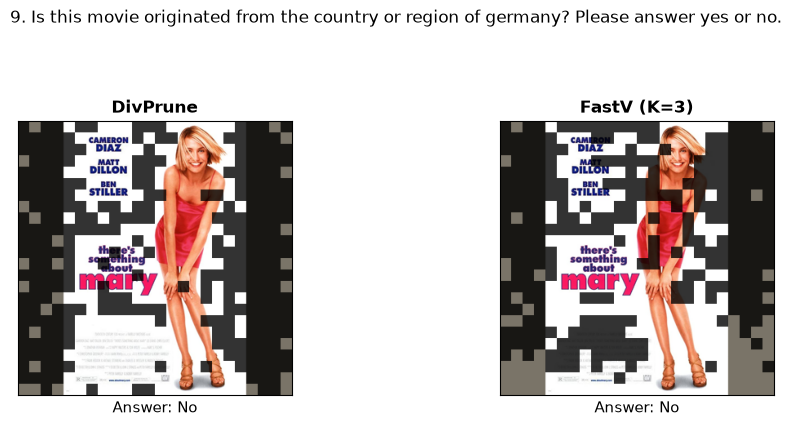

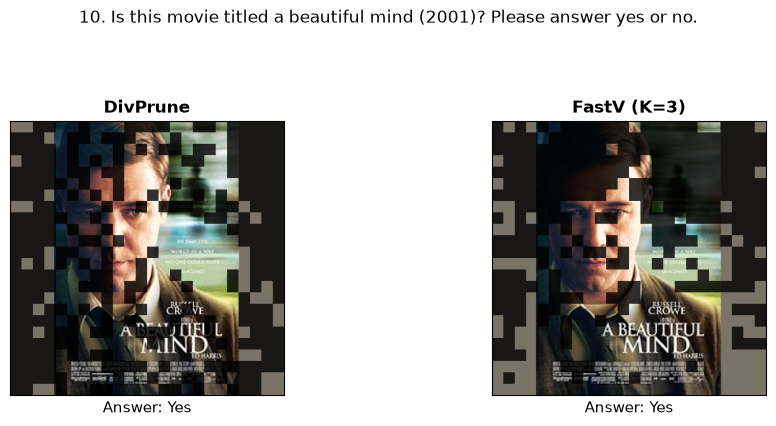

In [3]:
show_ratio("r0.5")


## Retention ratio: 70% (10 paired examples)

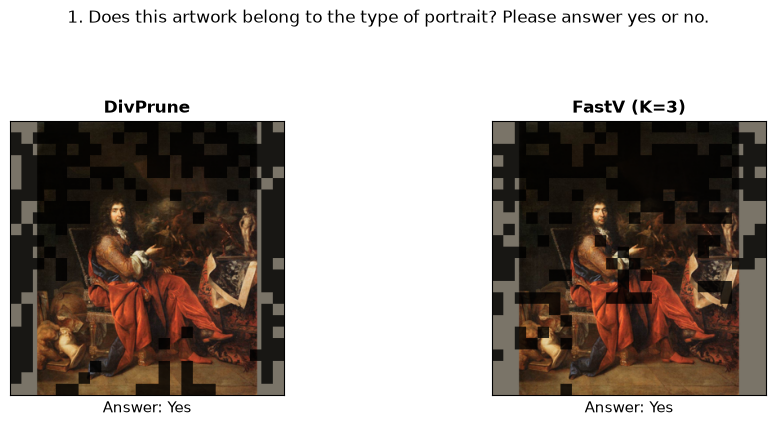

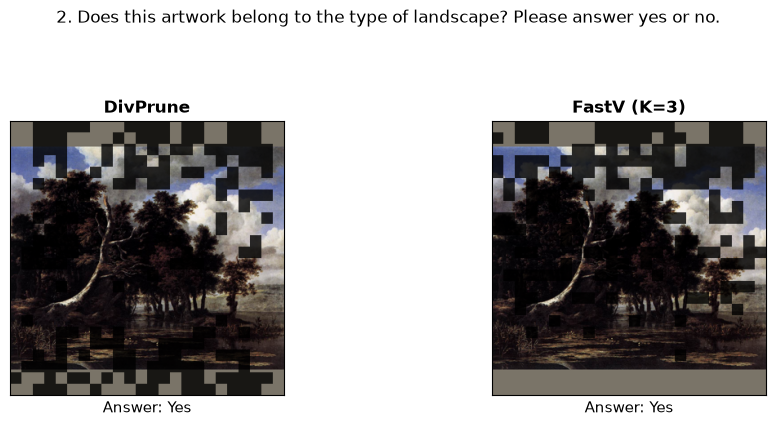

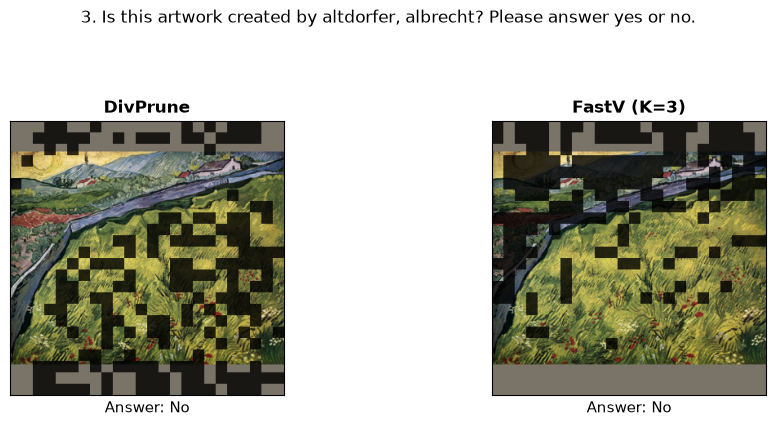

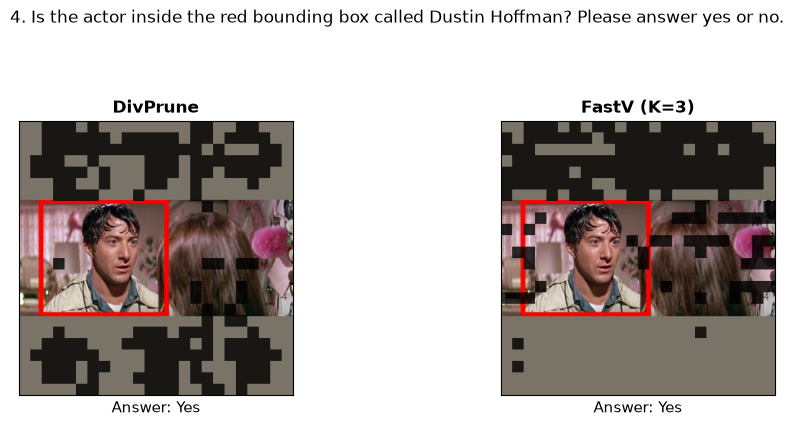

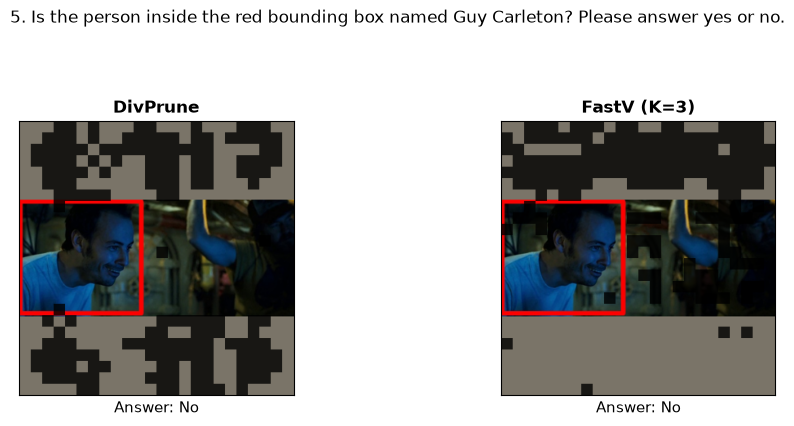

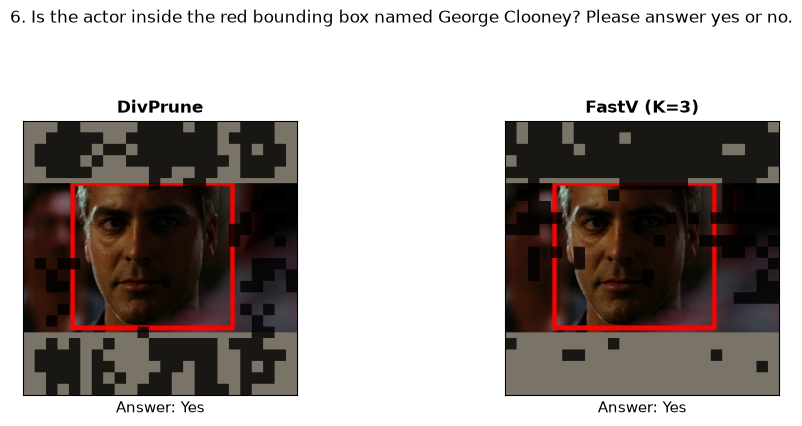

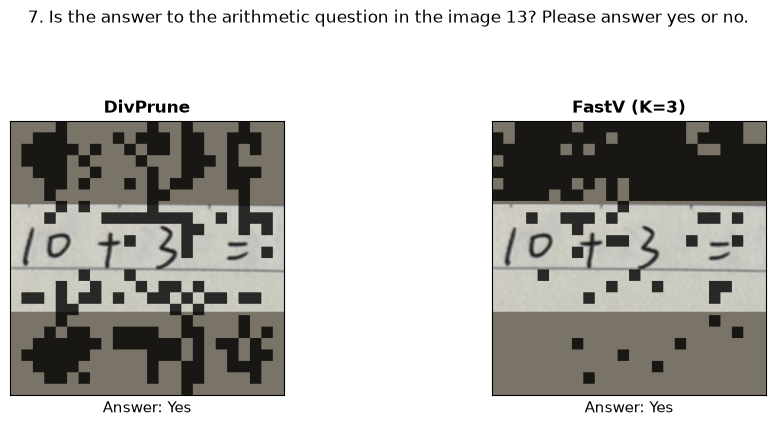

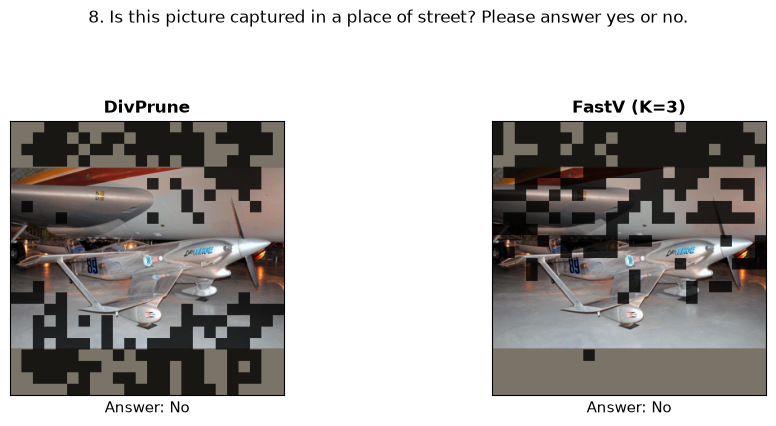

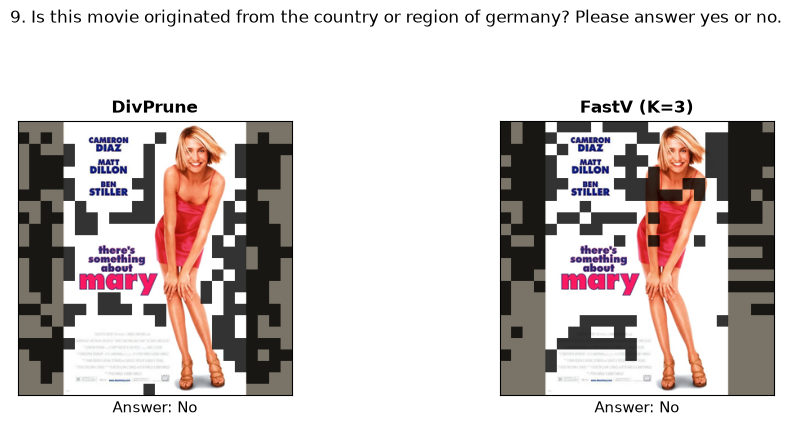

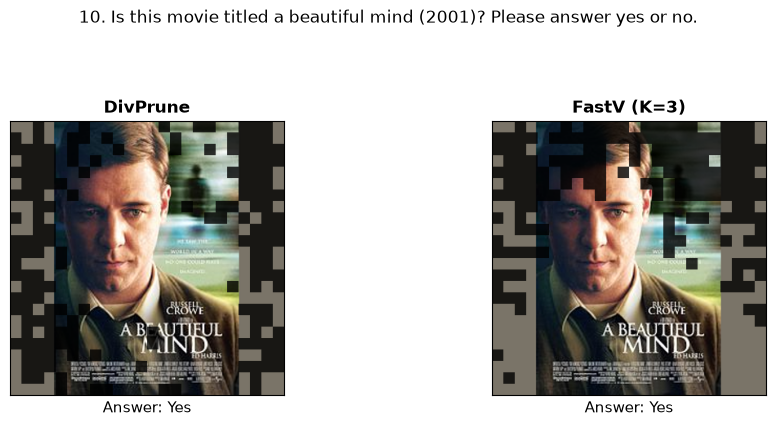

In [4]:
show_ratio("r0.7")
